In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import warnings

warnings.filterwarnings("ignore")

np.random.seed(42)
random.seed(42)

# Differential Evolution Parameters

NUM_EV = 20
TIME_SLOTS = 24

POPULATION_SIZE = 40
GENERATIONS = 100

F = 0.8
CR = 0.9

INDEPENDENT_RUNS = 10

# Charging Station Parameters

CHARGER_POWER = 7.0
STATION_CAPACITY = 50.0

print("=" * 55)
print("EV CHARGING OPTIMIZATION USING DIFFERENTIAL EVOLUTION")
print("=" * 55)

print("Number of EVs:", NUM_EV)
print("Time Slots:", TIME_SLOTS)
print("Population Size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Mutation Factor:", F)
print("Crossover Rate:", CR)
print("Independent Runs:", INDEPENDENT_RUNS)

print("\nLibraries imported successfully!")

EV CHARGING OPTIMIZATION USING DIFFERENTIAL EVOLUTION
Number of EVs: 20
Time Slots: 24
Population Size: 40
Generations: 100
Mutation Factor: 0.8
Crossover Rate: 0.9
Independent Runs: 10

Libraries imported successfully!


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import warnings

warnings.filterwarnings("ignore")

np.random.seed(42)
random.seed(42)

# Differential Evolution Parameters

NUM_EV = 20
TIME_SLOTS = 24

POPULATION_SIZE = 40
GENERATIONS = 100

F = 0.8
CR = 0.9

INDEPENDENT_RUNS = 10

# Charging Station Parameters

CHARGER_POWER = 7.0
STATION_CAPACITY = 50.0

print("=" * 55)
print("EV CHARGING OPTIMIZATION USING DIFFERENTIAL EVOLUTION")
print("=" * 55)

print("Number of EVs:", NUM_EV)
print("Time Slots:", TIME_SLOTS)
print("Population Size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Mutation Factor:", F)
print("Crossover Rate:", CR)
print("Independent Runs:", INDEPENDENT_RUNS)

print("\nLibraries imported successfully!")

EV CHARGING OPTIMIZATION USING DIFFERENTIAL EVOLUTION
Number of EVs: 20
Time Slots: 24
Population Size: 40
Generations: 100
Mutation Factor: 0.8
Crossover Rate: 0.9
Independent Runs: 10

Libraries imported successfully!


In [4]:
# Availability Matrix

availability = np.zeros((NUM_EV, TIME_SLOTS))

for i in range(NUM_EV):

    arrival = int(ev_data.loc[i, "Arrival_Time"])
    departure = int(ev_data.loc[i, "Departure_Time"])

    availability[i, arrival:departure] = 1


required_energy = ev_data["Required_Energy"].values


# Function to construct a feasible charging schedule

def create_schedule(priorities):

    priorities = priorities.reshape(NUM_EV, TIME_SLOTS)

    schedule = np.zeros((NUM_EV, TIME_SLOTS))

    remaining = required_energy.copy()

    for hour in range(TIME_SLOTS):

        available_evs = np.where(
            availability[:, hour] == 1
        )[0]

        # Calculate minimum charging needed now
        # to meet each EV's departure deadline.

        mandatory = {}

        for i in available_evs:

            future_slots = np.sum(
                availability[i, hour:]
            )

            minimum = max(
                0,
                remaining[i] -
                CHARGER_POWER * (future_slots - 1)
            )

            mandatory[i] = minimum

        mandatory_total = sum(mandatory.values())

        # Check station capacity

        if mandatory_total > STATION_CAPACITY + 1e-8:

            return None

        # Allocate mandatory energy first

        for i, power in mandatory.items():

            schedule[i, hour] = power

            remaining[i] -= power

        station_remaining = (
            STATION_CAPACITY - mandatory_total
        )

        # Allocate optional charging using DE priorities

        ordered_evs = sorted(
            available_evs,
            key=lambda i: priorities[i, hour],
            reverse=True
        )

        for i in ordered_evs:

            extra = min(
                CHARGER_POWER - schedule[i, hour],
                remaining[i],
                station_remaining
            )

            if extra > 0:

                schedule[i, hour] += extra

                remaining[i] -= extra

                station_remaining -= extra

    # Check final feasibility

    if np.any(remaining > 1e-5):

        return None

    return schedule


# Objective Function

def objective_function(solution):

    schedule = create_schedule(solution)

    if schedule is None:

        return 1e12

    # Minimize total electricity cost

    total_cost = np.sum(
        schedule * electricity_prices
    )

    # Small penalty to avoid unnecessary peak loads

    hourly_load = np.sum(schedule, axis=0)

    peak_penalty = 0.001 * np.sum(
        hourly_load ** 2
    )

    return total_cost + peak_penalty


print("Charging constraints initialized!")

print("Maximum individual charging power:",
      CHARGER_POWER, "kW")

print("Maximum station capacity:",
      STATION_CAPACITY, "kW")

print("All charging constraints configured!")

Charging constraints initialized!
Maximum individual charging power: 7.0 kW
Maximum station capacity: 50.0 kW
All charging constraints configured!


In [5]:
# Initialize Population

DIMENSIONS = NUM_EV * TIME_SLOTS


def initialize_population():

    return np.random.uniform(
        0, 1,
        (POPULATION_SIZE, DIMENSIONS)
    )


# Mutation Operation

def mutation(population, target_index):

    candidates = [
        i for i in range(POPULATION_SIZE)
        if i != target_index
    ]

    a, b, c = random.sample(candidates, 3)

    mutant = (
        population[a] +
        F * (population[b] - population[c])
    )

    return np.clip(mutant, 0, 1)


# Crossover Operation

def crossover(target, mutant):

    trial = target.copy()

    j_rand = random.randint(0, DIMENSIONS - 1)

    for j in range(DIMENSIONS):

        if random.random() < CR or j == j_rand:

            trial[j] = mutant[j]

    return trial


# Selection Operation

def selection(target, trial):

    if objective_function(trial) < objective_function(target):

        return trial.copy()

    return target.copy()


print("Differential Evolution operators implemented!")

print("1. Population Initialization")
print("2. Mutation")
print("3. Crossover")
print("4. Selection")

Differential Evolution operators implemented!
1. Population Initialization
2. Mutation
3. Crossover
4. Selection


In [6]:
def differential_evolution():

    population = initialize_population()

    fitness_values = np.array([

        objective_function(individual)

        for individual in population

    ])

    best_index = np.argmin(fitness_values)

    best_solution = population[best_index].copy()

    best_fitness = fitness_values[best_index]

    convergence = []

    average_fitness = []

    for generation in range(GENERATIONS):

        for i in range(POPULATION_SIZE):

            target = population[i]

            mutant = mutation(population, i)

            trial = crossover(target, mutant)

            trial_fitness = objective_function(trial)

            if trial_fitness < fitness_values[i]:

                population[i] = trial

                fitness_values[i] = trial_fitness

            if fitness_values[i] < best_fitness:

                best_fitness = fitness_values[i]

                best_solution = population[i].copy()

        convergence.append(best_fitness)

        average_fitness.append(
            np.mean(fitness_values)
        )

        if (generation + 1) % 10 == 0:

            print(
                f"Generation {generation+1}: "
                f"Best Cost = ₹{best_fitness:.2f}"
            )

    return (
        best_solution,
        best_fitness,
        convergence,
        average_fitness
    )


print("STARTING DIFFERENTIAL EVOLUTION")
print("=" * 50)

best_solution, best_fitness, convergence, average_fitness = (
    differential_evolution()
)

optimized_schedule = create_schedule(best_solution)

print("\nOPTIMIZATION COMPLETED!")

print("Best Objective Value:", round(best_fitness, 2))

print("Optimized Charging Cost:",
      round(np.sum(
          optimized_schedule * electricity_prices
      ), 2))

STARTING DIFFERENTIAL EVOLUTION
Generation 10: Best Cost = ₹3831.42
Generation 20: Best Cost = ₹3831.23
Generation 30: Best Cost = ₹3831.23
Generation 40: Best Cost = ₹3831.23
Generation 50: Best Cost = ₹3831.23
Generation 60: Best Cost = ₹3831.23
Generation 70: Best Cost = ₹3831.23
Generation 80: Best Cost = ₹3831.23
Generation 90: Best Cost = ₹3831.23
Generation 100: Best Cost = ₹3831.23

OPTIMIZATION COMPLETED!
Best Objective Value: 3831.23
Optimized Charging Cost: 3802.32


In [7]:
# Baseline Charging Strategy:
# Prioritize vehicles with earlier departure deadlines.

baseline_priorities = np.zeros(
    (NUM_EV, TIME_SLOTS)
)

for i in range(NUM_EV):

    for hour in range(TIME_SLOTS):

        baseline_priorities[i, hour] = (
            1 / max(
                1,
                ev_data.loc[i, "Departure_Time"] - hour
            )
        )

baseline_schedule = create_schedule(
    baseline_priorities.flatten()
)


# Calculate charging costs

baseline_cost = np.sum(
    baseline_schedule * electricity_prices
)

optimized_cost = np.sum(
    optimized_schedule * electricity_prices
)


# Energy calculations

baseline_energy = np.sum(baseline_schedule)

optimized_energy = np.sum(optimized_schedule)

cost_saving = baseline_cost - optimized_cost

saving_percentage = (
    cost_saving / baseline_cost
) * 100


# Calculate EV completion

delivered_energy = np.sum(
    optimized_schedule,
    axis=1
)

completion = (
    delivered_energy / required_energy
) * 100


# Print comparison

print("=" * 55)

print("BASELINE VS DE OPTIMIZED RESULTS")

print("=" * 55)

print("\nBASELINE COST: ₹", round(baseline_cost, 2))

print("OPTIMIZED COST: ₹", round(optimized_cost, 2))

print("COST SAVINGS: ₹", round(cost_saving, 2))

print("COST REDUCTION:",
      round(saving_percentage, 2), "%")

print("\nBASELINE ENERGY:",
      round(baseline_energy, 2), "kWh")

print("OPTIMIZED ENERGY:",
      round(optimized_energy, 2), "kWh")

print("\nAVERAGE CHARGING COMPLETION:",
      round(np.mean(completion), 2), "%")

print("\nFULLY CHARGED EVs:",
      np.sum(completion >= 99.99), "/", NUM_EV)


# Verify constraints

hourly_load = np.sum(
    optimized_schedule,
    axis=0
)

print("\nCONSTRAINT VALIDATION")

print("Maximum Station Load:",
      round(np.max(hourly_load), 2), "kW")

print("Station Capacity:",
      STATION_CAPACITY, "kW")

print("All EVs Fully Charged:",
      np.all(completion >= 99.99))

print("Station Capacity Respected:",
      np.max(hourly_load) <= STATION_CAPACITY + 1e-5)

print("Charging Availability Respected:",
      np.all(
          optimized_schedule[availability == 0] < 1e-5
      ))

print("Individual Charger Limits Respected:",
      np.max(optimized_schedule) <= CHARGER_POWER + 1e-5)

BASELINE VS DE OPTIMIZED RESULTS

BASELINE COST: ₹ 3844.61
OPTIMIZED COST: ₹ 3802.32
COST SAVINGS: ₹ 42.29
COST REDUCTION: 1.1 %

BASELINE ENERGY: 675.69 kWh
OPTIMIZED ENERGY: 675.69 kWh

AVERAGE CHARGING COMPLETION: 100.0 %

FULLY CHARGED EVs: 20 / 20

CONSTRAINT VALIDATION
Maximum Station Load: 50.0 kW
Station Capacity: 50.0 kW
All EVs Fully Charged: True
Station Capacity Respected: True
Charging Availability Respected: True
Individual Charger Limits Respected: True


In [8]:
print("RUNNING INDEPENDENT EXPERIMENTS")
print("=" * 50)

run_results = []

for run in range(INDEPENDENT_RUNS):

    solution, fitness, history, avg_history = (
        differential_evolution()
    )

    schedule = create_schedule(solution)

    actual_cost = np.sum(
        schedule * electricity_prices
    )

    run_results.append(actual_cost)

    print(
        f"Run {run+1}: "
        f"Charging Cost = ₹{actual_cost:.2f}"
    )


run_results = np.array(run_results)

print("\nSTATISTICAL ANALYSIS")

print("Best Cost: ₹", round(np.min(run_results), 2))

print("Worst Cost: ₹", round(np.max(run_results), 2))

print("Mean Cost: ₹", round(np.mean(run_results), 2))

print("Standard Deviation:",
      round(np.std(run_results), 2))

RUNNING INDEPENDENT EXPERIMENTS
Generation 10: Best Cost = ₹3831.68
Generation 20: Best Cost = ₹3831.23
Generation 30: Best Cost = ₹3831.23
Generation 40: Best Cost = ₹3831.23
Generation 50: Best Cost = ₹3831.23
Generation 60: Best Cost = ₹3831.23
Generation 70: Best Cost = ₹3831.23
Generation 80: Best Cost = ₹3831.23
Generation 90: Best Cost = ₹3831.23
Generation 100: Best Cost = ₹3831.23
Run 1: Charging Cost = ₹3802.32
Generation 10: Best Cost = ₹3831.31
Generation 20: Best Cost = ₹3831.23
Generation 30: Best Cost = ₹3831.23
Generation 40: Best Cost = ₹3831.23
Generation 50: Best Cost = ₹3831.23
Generation 60: Best Cost = ₹3831.23
Generation 70: Best Cost = ₹3831.23
Generation 80: Best Cost = ₹3831.23
Generation 90: Best Cost = ₹3831.23
Generation 100: Best Cost = ₹3831.23
Run 2: Charging Cost = ₹3802.32
Generation 10: Best Cost = ₹3831.45
Generation 20: Best Cost = ₹3831.23
Generation 30: Best Cost = ₹3831.23
Generation 40: Best Cost = ₹3831.23
Generation 50: Best Cost = ₹3831.23
Ge

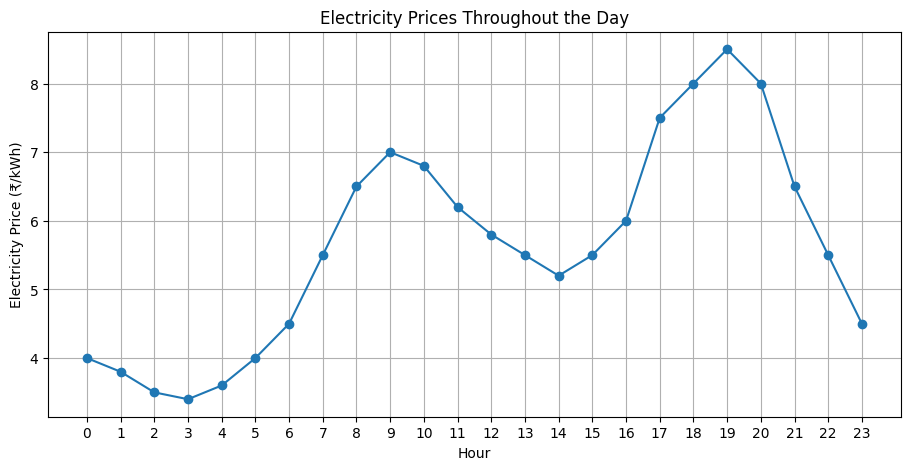

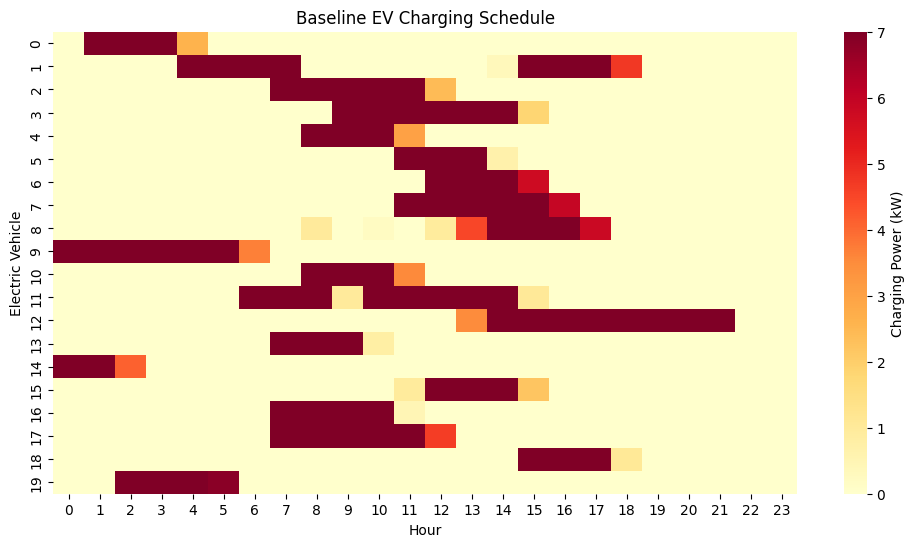

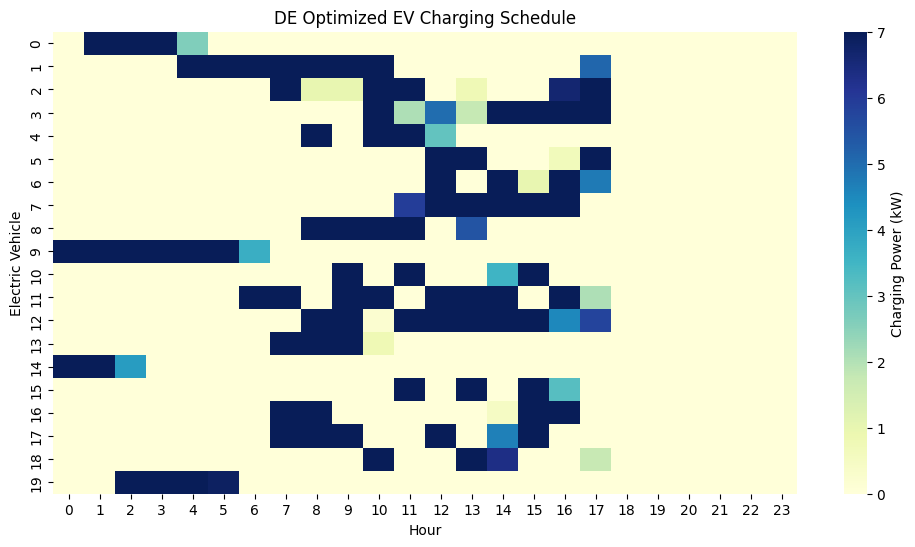

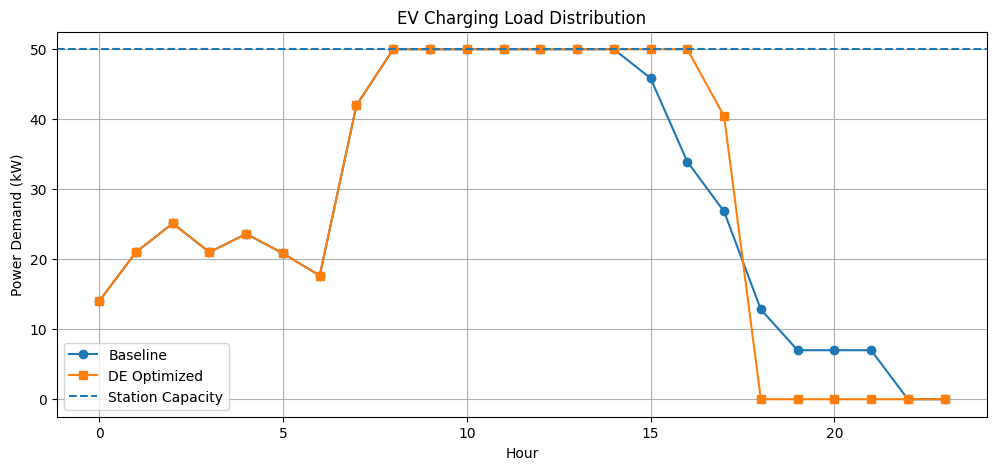

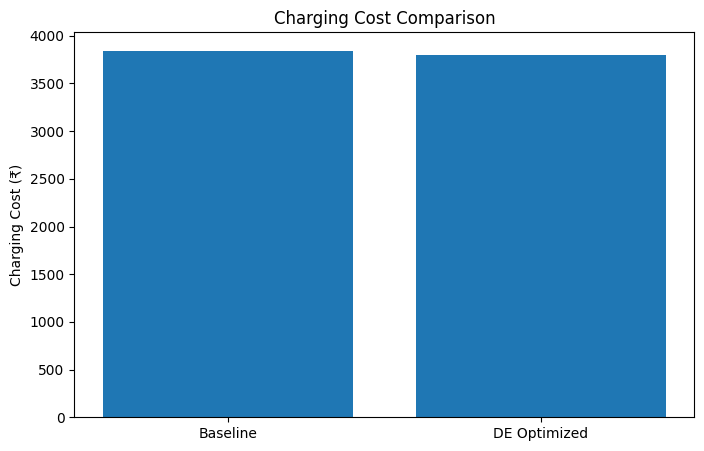

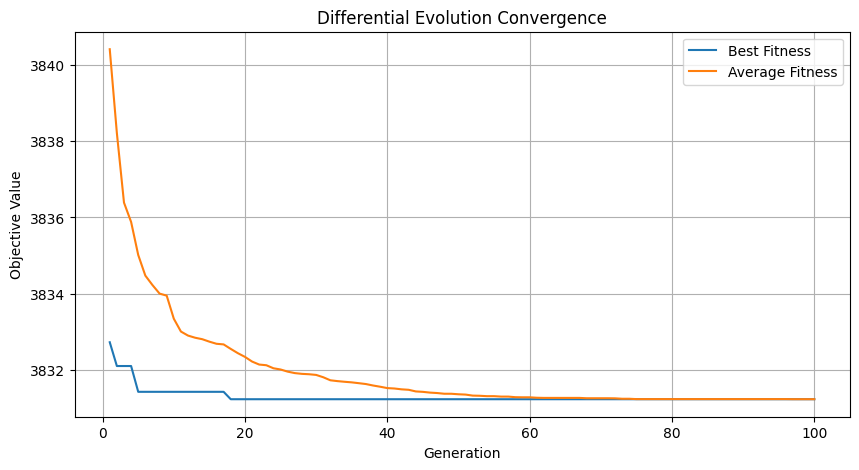

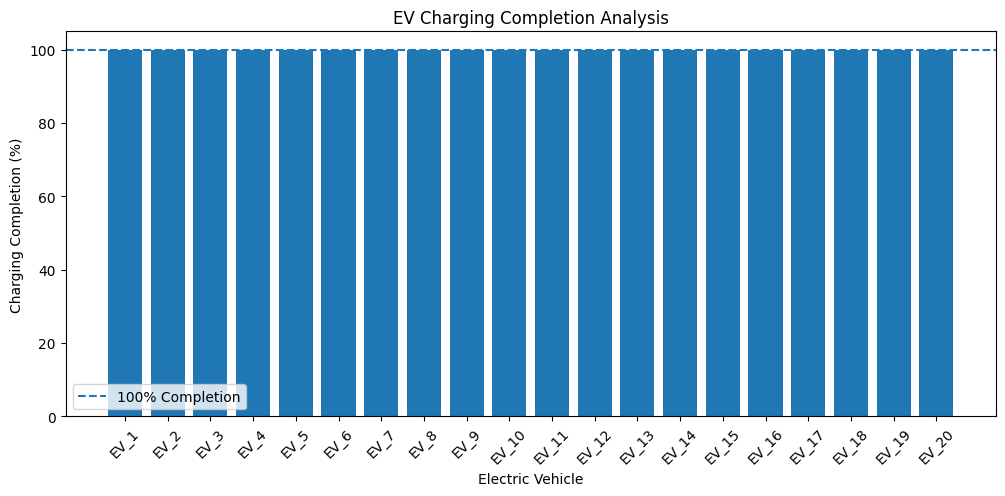

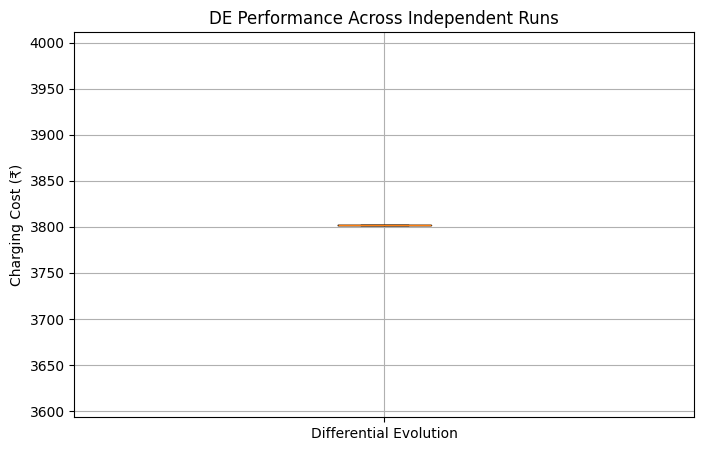

ALL 8 GRAPHS GENERATED SUCCESSFULLY!


In [9]:
# GRAPH 1: Electricity Prices

plt.figure(figsize=(11, 5))

plt.plot(
    range(24),
    electricity_prices,
    marker="o"
)

plt.xlabel("Hour")

plt.ylabel("Electricity Price (₹/kWh)")

plt.title("Electricity Prices Throughout the Day")

plt.xticks(range(24))

plt.grid(True)

plt.show()


# GRAPH 2: Baseline Charging Schedule

plt.figure(figsize=(12, 6))

sns.heatmap(
    baseline_schedule,
    cmap="YlOrRd",
    cbar_kws={"label": "Charging Power (kW)"}
)

plt.xlabel("Hour")

plt.ylabel("Electric Vehicle")

plt.title("Baseline EV Charging Schedule")

plt.show()


# GRAPH 3: Optimized Charging Schedule

plt.figure(figsize=(12, 6))

sns.heatmap(
    optimized_schedule,
    cmap="YlGnBu",
    cbar_kws={"label": "Charging Power (kW)"}
)

plt.xlabel("Hour")

plt.ylabel("Electric Vehicle")

plt.title("DE Optimized EV Charging Schedule")

plt.show()


# GRAPH 4: Load Distribution

baseline_load = np.sum(
    baseline_schedule,
    axis=0
)

optimized_load = np.sum(
    optimized_schedule,
    axis=0
)

plt.figure(figsize=(12, 5))

plt.plot(
    range(24),
    baseline_load,
    marker="o",
    label="Baseline"
)

plt.plot(
    range(24),
    optimized_load,
    marker="s",
    label="DE Optimized"
)

plt.axhline(
    STATION_CAPACITY,
    linestyle="--",
    label="Station Capacity"
)

plt.xlabel("Hour")

plt.ylabel("Power Demand (kW)")

plt.title("EV Charging Load Distribution")

plt.legend()

plt.grid(True)

plt.show()


# GRAPH 5: Cost Comparison

plt.figure(figsize=(8, 5))

plt.bar(
    ["Baseline", "DE Optimized"],
    [baseline_cost, optimized_cost]
)

plt.ylabel("Charging Cost (₹)")

plt.title("Charging Cost Comparison")

plt.show()


# GRAPH 6: Convergence Curve

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    convergence,
    label="Best Fitness"
)

plt.plot(
    range(1, GENERATIONS + 1),
    average_fitness,
    label="Average Fitness"
)

plt.xlabel("Generation")

plt.ylabel("Objective Value")

plt.title("Differential Evolution Convergence")

plt.legend()

plt.grid(True)

plt.show()


# GRAPH 7: EV Charging Completion

plt.figure(figsize=(12, 5))

plt.bar(
    ev_data["EV_ID"],
    completion
)

plt.axhline(
    100,
    linestyle="--",
    label="100% Completion"
)

plt.xlabel("Electric Vehicle")

plt.ylabel("Charging Completion (%)")

plt.title("EV Charging Completion Analysis")

plt.xticks(rotation=45)

plt.legend()

plt.show()


# GRAPH 8: Statistical Analysis

plt.figure(figsize=(8, 5))

plt.boxplot(
    run_results,
    labels=["Differential Evolution"]
)

plt.ylabel("Charging Cost (₹)")

plt.title("DE Performance Across Independent Runs")

plt.grid(True)

plt.show()


print("ALL 8 GRAPHS GENERATED SUCCESSFULLY!")

In [10]:
# Export EV dataset

ev_data.to_csv(
    "EV_Dataset.csv",
    index=False
)


# Export optimized charging schedule

pd.DataFrame(
    optimized_schedule,
    index=ev_data["EV_ID"],
    columns=[f"Hour_{i}" for i in range(24)]
).to_csv(
    "Optimized_Charging_Schedule.csv"
)


# Export baseline charging schedule

pd.DataFrame(
    baseline_schedule,
    index=ev_data["EV_ID"],
    columns=[f"Hour_{i}" for i in range(24)]
).to_csv(
    "Baseline_Charging_Schedule.csv"
)


# Export convergence results

pd.DataFrame({

    "Generation": range(1, GENERATIONS + 1),

    "Best_Fitness": convergence,

    "Average_Fitness": average_fitness

}).to_csv(
    "DE_Convergence_Results.csv",
    index=False
)


# Export statistical results

pd.DataFrame({

    "Run": range(1, INDEPENDENT_RUNS + 1),

    "Charging_Cost": run_results

}).to_csv(
    "DE_Statistical_Results.csv",
    index=False
)


# Export performance comparison

pd.DataFrame({

    "Metric": [
        "Baseline Cost",
        "Optimized Cost",
        "Cost Savings",
        "Cost Reduction",
        "Average Charging Completion",
        "Maximum Station Load",
        "Total EVs"
    ],

    "Value": [
        baseline_cost,
        optimized_cost,
        cost_saving,
        saving_percentage,
        np.mean(completion),
        np.max(optimized_load),
        NUM_EV
    ]

}).to_csv(
    "DE_Performance_Comparison.csv",
    index=False
)


print("=" * 55)

print("PROJECT EXECUTION COMPLETED!")

print("=" * 55)

print("\nFINAL RESULTS")

print("Baseline Cost: ₹", round(baseline_cost, 2))

print("Optimized Cost: ₹", round(optimized_cost, 2))

print("Cost Reduction:", round(saving_percentage, 2), "%")

print("Charging Completion:",
      round(np.mean(completion), 2), "%")

print("Maximum Station Load:",
      round(np.max(optimized_load), 2), "kW")

print("\nGENERATED FILES")

print("1. EV_Dataset.csv")
print("2. Optimized_Charging_Schedule.csv")
print("3. Baseline_Charging_Schedule.csv")
print("4. DE_Convergence_Results.csv")
print("5. DE_Statistical_Results.csv")
print("6. DE_Performance_Comparison.csv")

print("\nALL EXPERIMENTS COMPLETED!")

PROJECT EXECUTION COMPLETED!

FINAL RESULTS
Baseline Cost: ₹ 3844.61
Optimized Cost: ₹ 3802.32
Cost Reduction: 1.1 %
Charging Completion: 100.0 %
Maximum Station Load: 50.0 kW

GENERATED FILES
1. EV_Dataset.csv
2. Optimized_Charging_Schedule.csv
3. Baseline_Charging_Schedule.csv
4. DE_Convergence_Results.csv
5. DE_Statistical_Results.csv
6. DE_Performance_Comparison.csv

ALL EXPERIMENTS COMPLETED!
